# Week 3 Neural Networks with Time Series Data : Vibration → remaining useful life 

## Machine Learning for Engineering Applications

## By the end of this seminar you should be able to:

* Learn several ways to process your time series data for regression, and understanding the impact of these steps on the final model.
* Learn how to implement a typical ANN and a 1DCNN
* Learn the hyperparameters involved during NN training and their impact on the resulting model.
* Compare a small **statistical-feature ANN** with a **raw-window 1D CNN**, predicting remaining useful life (RUL) in hours.

**Setup:** put this notebook and `vibration_rul_dataset.csv` in the same folder, select a Python kernel and Run All. Change `CSV_PATH` below if your CSV is elsewhere. 

The CSV contains 738 separate one-second recordings from 18  machines, at 1,024 Hz. `sample_0000` … `sample_1023` are vibration values in arbitrary units. Metadata columns are `record_id`, `machine_id`, `age_hours`, `rul_hours`, `state` and `sample_rate_hz`. Only sample columns are model inputs; metadata supplies labels, grouping and inspection.

These bursts are spread across each machine's  life and **are not contiguous**. Increasing noise and damped bearing-like impacts represent degradation. Lifetimes, sensor gains, speeds and damage rates vary. This is a teaching simulation, not a validated bearing physics model. Early-life RUL can be ambiguous; real deployment also depends on operating conditions and future loads.

The defaults run correctly. Optional mistake switches are clearly marked and off by default.

In [1]:
# Uncomment once if packages are missing, then restart the kernel.
# %pip install numpy pandas matplotlib scikit-learn tensorflow
# Keras 3 is included with TensorFlow. The notebook uses tensorflow.keras.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 7
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

CSV_PATH = Path('data/vibration_rul_dataset.csv')
data = pd.read_csv(CSV_PATH)
# Sort by sample number, rather than relying on the CSV column order.
sample_cols = sorted([c for c in data.columns if c.startswith('sample_') and c.split('_')[1].isdigit()],
                     key=lambda c: int(c.split('_')[1]))
assert len(sample_cols) == 1024, 'Expected 1,024 sample columns in this dataset.'
assert data['sample_rate_hz'].nunique() == 1, 'Recordings must share one sample rate.'
signals = data[sample_cols].to_numpy(dtype='float32')
meta = data[['record_id', 'machine_id', 'age_hours', 'rul_hours', 'state']].copy()
fs = int(data['sample_rate_hz'].iloc[0])
assert meta.record_id.is_unique
assert np.isfinite(signals).all() and np.isfinite(meta.rul_hours).all()
assert meta.rul_hours.ge(0).all()
print(signals.shape, 'sample rate:', fs, 'Hz')
meta.head()

(738, 1024) sample rate: 1024 Hz


,record_id,machine_id,age_hours,rul_hours,state
0,0,0,0.000000,210.00764,healthy
1,1,0,5.250191,204.75745,healthy
2,2,0,10.500382,199.50726,healthy
3,3,0,15.750573,194.25706,healthy
4,4,0,21.000764,189.00687,healthy


In [3]:
print(fs)

1024


## 1. Inspect three states
Time here is time within a burst. It is different from operating age in hours. State bins are healthy >120 h, degrading >40 to 120 h and near failure 0 to 40 h; these are descriptive teaching labels.

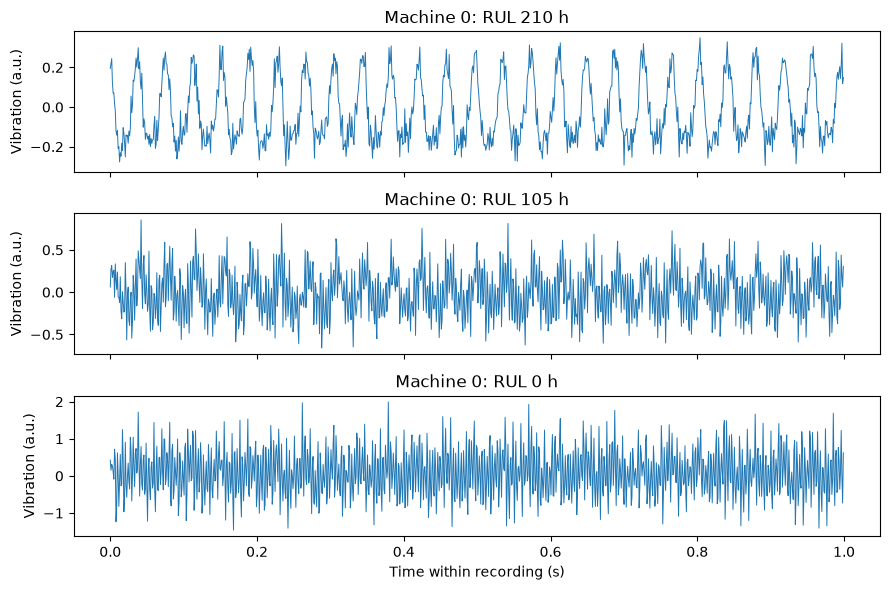

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, row in zip(axes, [0, 20, 40]):
    ax.plot(np.arange(signals.shape[1])/fs, signals[row], linewidth=0.7)
    ax.set_title(f"Machine {meta.machine_id.iloc[row]}: RUL {meta.rul_hours.iloc[row]:.0f} h")
    ax.set_ylabel('Vibration (a.u.)')
axes[-1].set_xlabel('Time within recording (s)')
plt.tight_layout()

## 2. Create windows and choose student parameters
A window inherits its burst's RUL because one second is negligible compared with hours. Never concatenate separate bursts as each burst might have been taken hours apart. Overlap by creating a sliding window when partioning your signal increases correlated examples, not the number of independent samples.

In [5]:
WINDOW = 256  # try 128 or 512 samples
STRIDE = 256  # use WINDOW for no overlap; try WINDOW // 2
EPOCHS = 30
BATCH_SIZE = 64
LR = 0.001
WIDTH = 16

# Optional : enable ONE and explain the effect.
RANDOM_WINDOW_SPLIT = True  # watch out! Same machine may appear in all three sets
PER_WINDOW_STANDARDIZE = False  # can remove useful amplitude information. If you standardise per window, you are creating a more difficult problem as your data no longer captures changes in amplitude


assert 16 <= WINDOW <= signals.shape[1]
assert STRIDE > 0 and EPOCHS > 0
starts = range(0, signals.shape[1] - WINDOW + 1, STRIDE)
X = np.stack([signal[s:s+WINDOW] for signal in signals for s in starts])
# These are row positions, so a reordered CSV still maps each window correctly.
record_rows = np.repeat(np.arange(len(meta)), len(starts))
record_ids = meta.record_id.to_numpy()[record_rows]
y = meta.rul_hours.to_numpy(dtype='float32')[record_rows]
groups = meta.machine_id.to_numpy()[record_rows]
print(X.shape, 'windows;', WINDOW/fs, 'seconds per window')

(2952, 256) windows; 0.25 seconds per window


## 3. Hold out whole machines
With a machine-level split, twelve machines train, three validate and three test. A random-window split can share machines across sets. Validation chooses the epoch. Test scores are for the final model, not repeated tuning. Fit preprocessing using training data only.

For a different dataset, choose a split that matches deployment: unseen machines, future times, or new conditions. Randomly splitting windows from one life trajectory can give optimistic scores.

In [6]:
ids = np.arange(len(X))
if RANDOM_WINDOW_SPLIT:
    train_idx, rest = train_test_split(ids, test_size=1/3, random_state=SEED)
    val_idx, test_idx = train_test_split(rest, test_size=0.5, random_state=SEED)
else:
    machines = np.random.default_rng(SEED).permutation(np.unique(groups))
    assert len(machines) == 18, 'Adapt the grouped split if using a different dataset.'
    train_idx = ids[np.isin(groups, machines[:12])]
    val_idx = ids[np.isin(groups, machines[12:15])]
    test_idx = ids[np.isin(groups, machines[15:])]
    assert not (set(groups[train_idx]) & set(groups[val_idx]))
    assert not (set(groups[train_idx]) & set(groups[test_idx]))
    assert not (set(groups[val_idx]) & set(groups[test_idx]))
for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    print(name, len(idx), 'windows from', len(np.unique(groups[idx])), 'machines')

X_work = X.copy()
if PER_WINDOW_STANDARDIZE:
    X_work = (X_work - X_work.mean(axis=1, keepdims=True)) / (X_work.std(axis=1, keepdims=True) + 1e-8)
y_scale = float(y[train_idx].max())
y_scaled = y / y_scale  # models predict scaled hours, converted back below

train 1968 windows from 18 machines
validation 492 windows from 18 machines
test 492 windows from 18 machines


## 4. Five statistical features → ANN
RMS, standard deviation, peak-to-peak, crest factor and Pearson kurtosis (Gaussian ≈ 3). Epsilon avoids division by zero. Some features are correlated; try removing one.

In [7]:
def features(windows):
    rms = np.sqrt(np.mean(windows**2, axis=1))
    std = windows.std(axis=1)
    peak_to_peak = np.ptp(windows, axis=1)
    crest = np.max(np.abs(windows), axis=1) / (rms + 1e-8)
    centered = windows - windows.mean(axis=1, keepdims=True)
    kurtosis = np.mean(centered**4, axis=1) / (std**4 + 1e-8)
    return np.column_stack([rms, std, peak_to_peak, crest, kurtosis])

F = features(X_work)
scaler = StandardScaler().fit(F[train_idx])
F_scaled = scaler.transform(F).astype('float32')
keras.utils.set_random_seed(SEED)
mlp = keras.Sequential([
    keras.Input(shape=(F_scaled.shape[1],)),
    layers.Dense(WIDTH, activation='relu'),
    layers.Dense(1),  # One linear RUL output (scaled hours)
], name='rul_ann')
mlp.summary()

Model: "rul_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113 (452.00 B)

 Trainable params: 113 (452.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. A shared Keras training function
Keras handles mini-batches and automatic differentiation inside `model.fit()`.
Adam minimises MSE on scaled RUL. `EarlyStopping` watches **validation MSE** and
`restore_best_weights=True` restores the best-performing epoch.
We report model predictions in hours by multiplying by `y_scale`.
A linear final layer can predict negative RUL; consider this limitation when interpreting results.

In [8]:
def fit_model(model, inputs):
    keras.utils.set_random_seed(SEED)
    inputs = np.asarray(inputs, dtype='float32')
    targets = y_scaled[:, None].astype('float32')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss='mse',
    )
    stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True,
    )
    history_obj = model.fit(
        inputs[train_idx], targets[train_idx],
        validation_data=(inputs[val_idx], targets[val_idx]),
        batch_size=BATCH_SIZE, epochs=EPOCHS,
        callbacks=[stopping], verbose=0,
    )
    # Keras predict() runs inference without a gradient update.
    pred_val = model.predict(inputs[val_idx], verbose=0).ravel() * y_scale
    pred_test = model.predict(inputs[test_idx], verbose=0).ravel() * y_scale
    history = np.column_stack([
        history_obj.history['loss'], history_obj.history['val_loss'],
    ])
    return pred_val, pred_test, history

val_mlp, pred_mlp, history_mlp = fit_model(mlp, F_scaled)
print('ANN validation MAE (h):', round(mean_absolute_error(y[val_idx], val_mlp), 2))

ANN validation MAE (h): 15.2


## 6. Raw windows → simple 1D CNN (Keras)
Keras `Conv1D` expects `(batch, samples, channels)` (channels **last**),
whereas PyTorch normally uses `(batch, channels, samples)`.
We have one vibration channel. Using a single mean and standard deviation from
**training data only** preserves relative amplitude differences between windows.
`padding='same'` preserves time length after each convolution; `MaxPooling1D`
reduces it; `GlobalAveragePooling1D` creates one feature per filter.

In [9]:
raw_mean = X_work[train_idx].mean()
raw_std = X_work[train_idx].std()
# Channels-last: (number of windows, samples per window, 1 channel).
X_cnn = ((X_work - raw_mean) / (raw_std + 1e-8))[:, :, None].astype('float32')
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    keras.Input(shape=(WINDOW, 1)),
    layers.Conv1D(WIDTH, kernel_size=9, padding='same', activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(WIDTH, kernel_size=9, padding='same', activation='relu'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(1),  # One linear RUL output
], name='rul_cnn')
cnn.summary()
val_cnn, pred_cnn, history_cnn = fit_model(cnn, X_cnn)
print('CNN validation MAE (h):', round(mean_absolute_error(y[val_idx], val_cnn), 2))

Model: "rul_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 256, 16)        │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 128, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 16)        │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

CNN validation MAE (h): 8.33


## 7. Evaluate against the training-mean baseline
Use validation MAE for student experiments. Run the test report once after selecting settings. Burst MAE averages predictions over windows of the same recording. Correlated windows are not independent tests: there are only three held-out machines.

        model  window MAE (h)  window RMSE (h)  burst MAE (h)
Mean baseline           49.43            57.71          49.68
          ANN           16.15            19.94          15.87
          CNN            8.21            10.52           8.10


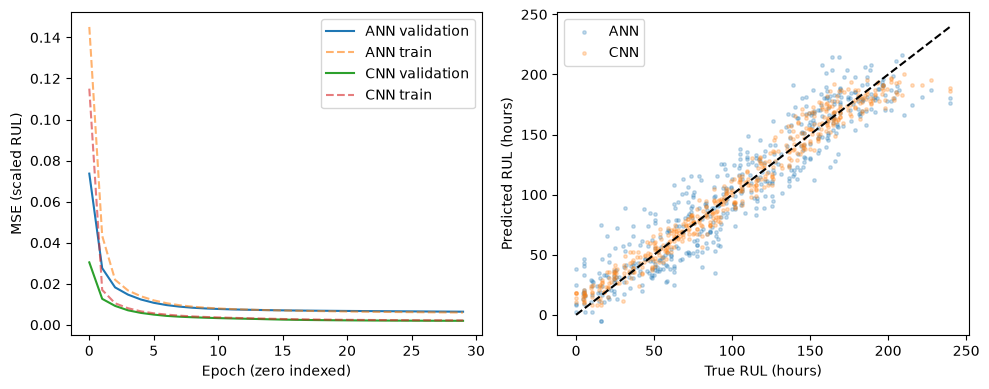

In [10]:
baseline = np.full(len(test_idx), y[train_idx].mean())
rows = []
for name, pred in [('Mean baseline', baseline), ('ANN', pred_mlp), ('CNN', pred_cnn)]:
    burst = pd.DataFrame({'record_id': record_ids[test_idx], 'truth': y[test_idx], 'pred': pred}).groupby('record_id').mean()
    rows.append({'model': name,
                 'window MAE (h)': mean_absolute_error(y[test_idx], pred),
                 'window RMSE (h)': np.sqrt(mean_squared_error(y[test_idx], pred)),
                 'burst MAE (h)': mean_absolute_error(burst.truth, burst.pred)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, history in [('ANN', history_mlp), ('CNN', history_cnn)]:
    axes[0].plot(history[:, 1], label=name + ' validation')
    axes[0].plot(history[:, 0], '--', alpha=0.6, label=name + ' train')
axes[0].set(xlabel='Epoch (zero indexed)', ylabel='MSE (scaled RUL)')
axes[0].legend()
for name, pred in [('ANN', pred_mlp), ('CNN', pred_cnn)]:
    axes[1].scatter(y[test_idx], pred, s=6, alpha=0.25, label=name)
axes[1].plot([0, y_scale], [0, y_scale], 'k--')
axes[1].set(xlabel='True RUL (hours)', ylabel='Predicted RUL (hours)')
axes[1].legend()
plt.tight_layout()

## 8. Your experiments: diagnose, fix, explain
Change one setting at a time and rerun from the parameter cell through training. Record **change | reason | validation MAE | conclusion**. Reserve the test cell for your final settings.

1. **Leakage:** enable `RANDOM_WINDOW_SPLIT`. Find machines shared by train and validation. Does a lower error prove better performance on unseen machines? Restore the grouped split.
2. **Amplitude:** enable `PER_WINDOW_STANDARDIZE`. Which statistical features become nearly constant? When could per-window normalisation help with sensor gain, and when does it remove useful degradation information? Restore training-only global scaling.
3. **Window size:** compare 128, 256 and 512 samples with a matching stride. Convert size to seconds and approximate shaft revolutions (about 25 Hz). Which physical patterns fit? Does overlap add independent evidence?
4. **Capacity:** try `WIDTH=4` or `64`, and `EPOCHS=5` or `80`. Compare train and validation curves. Count parameters with `cnn.count_params()`.
5. **Features:** remove crest factor or kurtosis from `features`. The ANN input size adapts automatically. Try RMS alone using `return rms[:, None]`. Compare validation MAE.
6. **Learning rate:** try 0.0001, 0.001 and 0.05. Distinguish slow learning from unstable training.
7. **Transfer to another dataset:** check units, sample rate, sensor placement, load/speed, failure definition, available labels and deployment split. Nine samples represent a different duration when sample rate changes. Update the sample-count check and machine split deliberately.